Comprehensive Exploratory Data Analysis (EDA) for 6 Diabetic Retinopathy (DR) Datasets

Datasets Evaluated: APTOS 2019, DDR, DeepDRiD, IDRiD, Messidor-2, EyePACS.
Problem Formulation: Ordinal Severity Classification (Grading 0 to 4).
Optimization Focus: Quadratic Weighted Kappa (QWK) & Data Imbalance/Quality Auditing.



In [1]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm import tqdm

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

# Set random seeds for research reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print(f"[INFO] Initialized environment with SEED={SEED}")



[INFO] Initialized environment with SEED=42


## 1. Dynamic Path Resolution & Configuration Dictionary

Automatic working directory discovery to ensure execution succeeds whether run from 
project root (`deep-learning-for-computer-vision/`) or nested subfolder (`notebooks/diabetic_retinopathy/`).



In [2]:
def get_base_path() -> str:
    """
    Dynamically finds relative path to `data/raw/` based on current working directory.
    """
    return os.path.join("../../../../data", "raw")

BASE_RAW_DIR = get_base_path()
print(f"[INFO] Resolved BASE_RAW_DIR: {BASE_RAW_DIR}")

# Central Configuration Dictionary mapping raw datasets to CSV label files & image directories
DATASET_CONFIG = {
    "APTOS": {
        "name": "APTOS 2019",
        "csv_path": os.path.join("aptos", "train_1.csv"),
        "img_dir": os.path.join("aptos", "train_images"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ".png"
    },
    "DDR": {
        "name": "DDR Dataset",
        "csv_path": os.path.join("ddr", "DR_grading.csv"),
        "img_dir": os.path.join("ddr", "DR_grading", "DR_grading"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ".jpg"
    },
    "DeepDRiD": {
        "name": "DeepDRiD",
        "csv_path": os.path.join("deepdrid", "DeepDRiD-master", "regular_fundus_images", "regular-fundus-training", "regular-fundus-training.csv"),
        "img_dir": os.path.join("deepdrid", "DeepDRiD-master", "regular_fundus_images", "regular-fundus-training", "Images"),
        "id_col": "image_id",
        "label_col": "patient_DR_Level",
        "id_suffix": ".jpg"
    },
    "IDRiD": {
        "name": "IDRiD",
        "csv_path": os.path.join("idrid", "idrid_labels.csv"),
        "img_dir": os.path.join("idrid", "Imagenes"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ".jpg"
    },
    "Messidor-2": {
        "name": "Messidor-2",
        "csv_path": os.path.join("messidor2preprocess", "messidor_data.csv"),
        "img_dir": os.path.join("messidor2preprocess", "messidor-2"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ""
    },
    "EyePACS": {
        "name": "EyePACS (Kaggle)",
        "csv_path": os.path.join("zipEyepacs", "trainLabels.csv", "trainLabels.csv"),
        "img_dir": os.path.join("zipEyepacs", "train"),
        "id_col": "image",
        "label_col": "level",
        "id_suffix": ".jpeg"
    }
}

# Fallback check for EyePACS CSV path if nested directory varies
eyepacs_alt_csv = os.path.join(BASE_RAW_DIR, "zipEyepacs", "trainLabels.csv")
if not os.path.exists(os.path.join(BASE_RAW_DIR, DATASET_CONFIG["EyePACS"]["csv_path"])) and os.path.isfile(eyepacs_alt_csv):
    DATASET_CONFIG["EyePACS"]["csv_path"] = os.path.join("zipEyepacs", "trainLabels.csv")

[INFO] Resolved BASE_RAW_DIR: ../../../../data\raw


## 2. Standardized Ingestion, Parsing & Sanity Check Logic



In [3]:
def parse_patient_and_side(image_id: str) -> tuple[str, str]:
    """
    Extracts patient_id and eye lateral side ('left'/'right') if present in image_id.
    """
    img_str = str(image_id).lower()
    side = "unknown"
    if "left" in img_str or "_l" in img_str:
        side = "left"
    elif "right" in img_str or "_r" in img_str:
        side = "right"
        
    patient_id = img_str.split("_")[0] if "_" in img_str else img_str
    return patient_id, side


def load_and_standardize_dataset(key: str, cfg: dict, base_dir: str) -> tuple[pd.DataFrame, dict]:
    """
    Loads raw CSV label file, standardizes column names to 'image_id' and 'level',
    runs data sanity audits, and extracts lateral eye metadata.
    """
    full_csv_path = os.path.join(base_dir, cfg["csv_path"])
    full_img_dir = os.path.join(base_dir, cfg["img_dir"])
    
    if not os.path.exists(full_csv_path):
        print(f"[WARNING] CSV path not found: {full_csv_path}")
        return pd.DataFrame(), {}

    raw_df = pd.read_csv(full_csv_path)
    
    # Handle DeepDRiD label column fallback if primary is missing
    label_col = cfg["label_col"]
    if label_col not in raw_df.columns:
        possible_labels = [c for c in raw_df.columns if "dr" in c.lower() or "level" in c.lower() or "diagnosis" in c.lower()]
        if possible_labels:
            label_col = possible_labels[0]
            
    df = raw_df[[cfg["id_col"], label_col]].copy()
    df.columns = ["image_id", "level"]
    df["dataset"] = cfg["name"]
    
    # Ensure correct file extension on image_id
    if cfg["id_suffix"]:
        df["image_file"] = df["image_id"].astype(str).apply(lambda x: x if x.endswith(cfg["id_suffix"]) else x + cfg["id_suffix"])
    else:
        df["image_file"] = df["image_id"].astype(str)
        
    df["full_path"] = df["image_file"].apply(lambda f: os.path.join(full_img_dir, f))
    
    # Sanity checks
    duplicate_count = df["image_id"].duplicated().sum()
    null_count = df["level"].isnull().sum()
    
    # Fill/Clean non-integer labels
    df["level"] = pd.to_numeric(df["level"], errors="coerce")
    invalid_label_count = (~df["level"].isin([0, 1, 2, 3, 4])).sum()
    
    df_clean = df.dropna(subset=["level"]).copy()
    df_clean["level"] = df_clean["level"].astype(int)
    df_clean = df_clean[df_clean["level"].isin([0, 1, 2, 3, 4])]
    
    # Patient & Lateral side parsing
    parsed_metadata = df_clean["image_id"].apply(parse_patient_and_side)
    df_clean["patient_id"] = [p[0] for p in parsed_metadata]
    df_clean["side"] = [p[1] for p in parsed_metadata]
    
    audit_summary = {
        "total_records": len(df),
        "valid_records": len(df_clean),
        "duplicates": duplicate_count,
        "null_labels": null_count,
        "invalid_labels": invalid_label_count,
        "unique_patients": df_clean["patient_id"].nunique(),
        "left_eyes": (df_clean["side"] == "left").sum(),
        "right_eyes": (df_clean["side"] == "right").sum()
    }
    
    return df_clean, audit_summary




## 3. Data Loading & Integrity Auditing Execution



In [4]:
dataset_dfs = {}
audit_summaries = {}

print("=== DATASET SANITY & INTEGRITY AUDIT REPORT ===")
for key, config in DATASET_CONFIG.items():
    df_std, summary = load_and_standardize_dataset(key, config, BASE_RAW_DIR)
    if not df_std.empty:
        dataset_dfs[key] = df_std
        audit_summaries[key] = summary
        print(f"\n--- {config['name']} ---")
        print(f"Total Rows: {summary['total_records']} | Valid DR Records: {summary['valid_records']}")
        print(f"Duplicates: {summary['duplicates']} | Missing NaNs: {summary['null_labels']} | Invalid Grade Range: {summary['invalid_labels']}")
        print(f"Unique Patients: {summary['unique_patients']} | Left Eyes: {summary['left_eyes']} | Right Eyes: {summary['right_eyes']}")

audit_df = pd.DataFrame(audit_summaries).T
print("\n=== AGGREGATED AUDIT TABLE ===")
print(audit_df[["total_records", "valid_records", "duplicates", "null_labels", "invalid_labels", "unique_patients"]])



=== DATASET SANITY & INTEGRITY AUDIT REPORT ===

--- APTOS 2019 ---
Total Rows: 2930 | Valid DR Records: 2930
Duplicates: 0 | Missing NaNs: 0 | Invalid Grade Range: 0
Unique Patients: 2930 | Left Eyes: 0 | Right Eyes: 0

--- DDR Dataset ---
Total Rows: 12522 | Valid DR Records: 12522
Duplicates: 0 | Missing NaNs: 0 | Invalid Grade Range: 0
Unique Patients: 12522 | Left Eyes: 0 | Right Eyes: 0

--- DeepDRiD ---
Total Rows: 1200 | Valid DR Records: 1200
Duplicates: 0 | Missing NaNs: 0 | Invalid Grade Range: 0
Unique Patients: 300 | Left Eyes: 599 | Right Eyes: 601

--- IDRiD ---
Total Rows: 455 | Valid DR Records: 455
Duplicates: 0 | Missing NaNs: 0 | Invalid Grade Range: 0
Unique Patients: 1 | Left Eyes: 0 | Right Eyes: 0

--- Messidor-2 ---
Total Rows: 1744 | Valid DR Records: 1744
Duplicates: 0 | Missing NaNs: 0 | Invalid Grade Range: 0
Unique Patients: 711 | Left Eyes: 0 | Right Eyes: 0

--- EyePACS (Kaggle) ---
Total Rows: 35126 | Valid DR Records: 35126
Duplicates: 0 | Missing NaNs

## 4. Class Distribution & Imbalance Analysis

Diabetic Retinopathy severity distribution across 5 ordinal grades:
- Level 0: No DR
- Level 1: Mild DR
- Level 2: Moderate DR
- Level 3: Severe DR
- Level 4: Proliferative DR



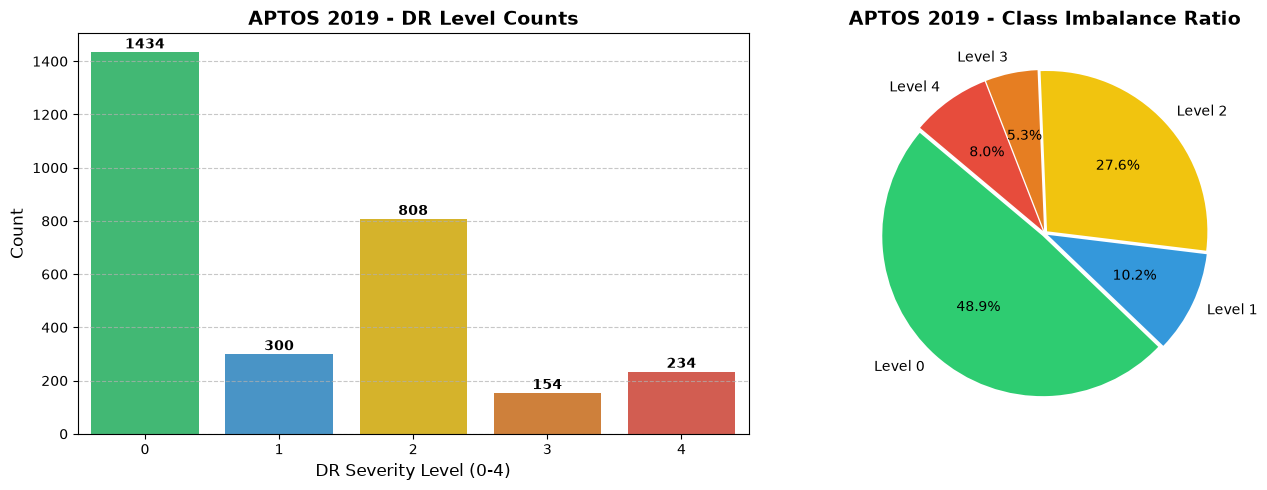

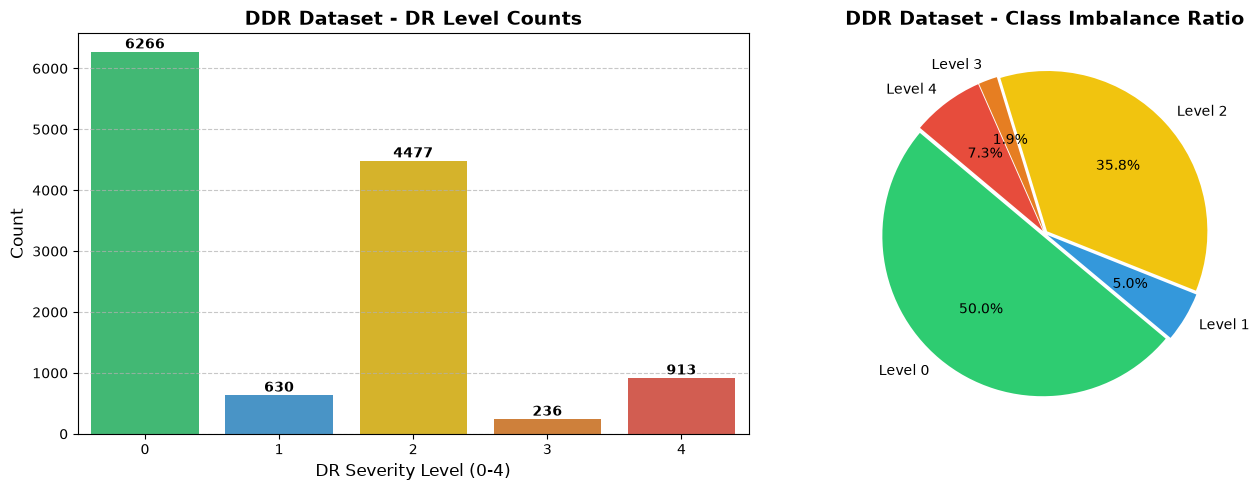

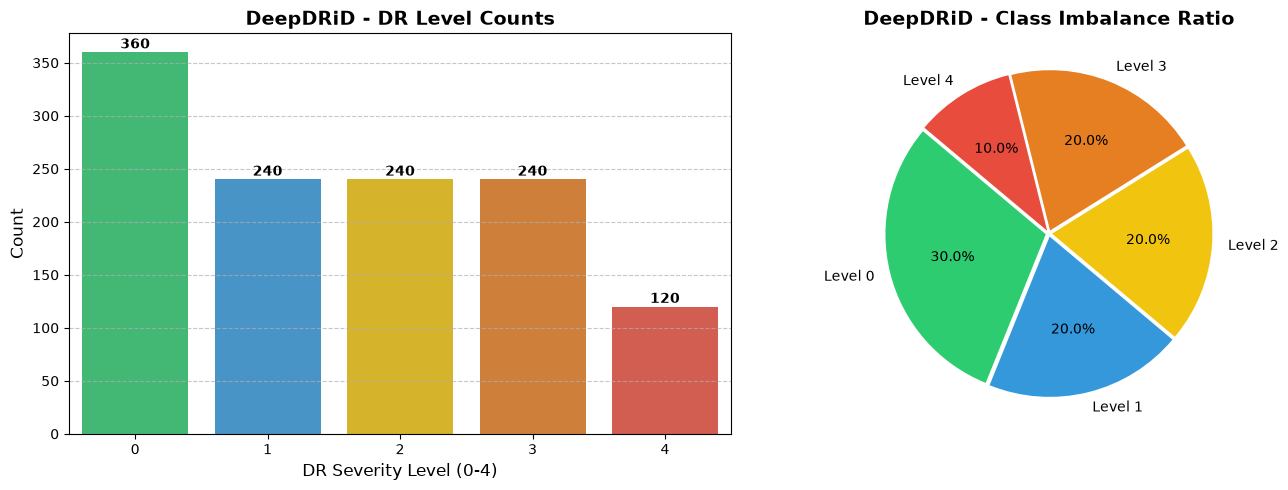

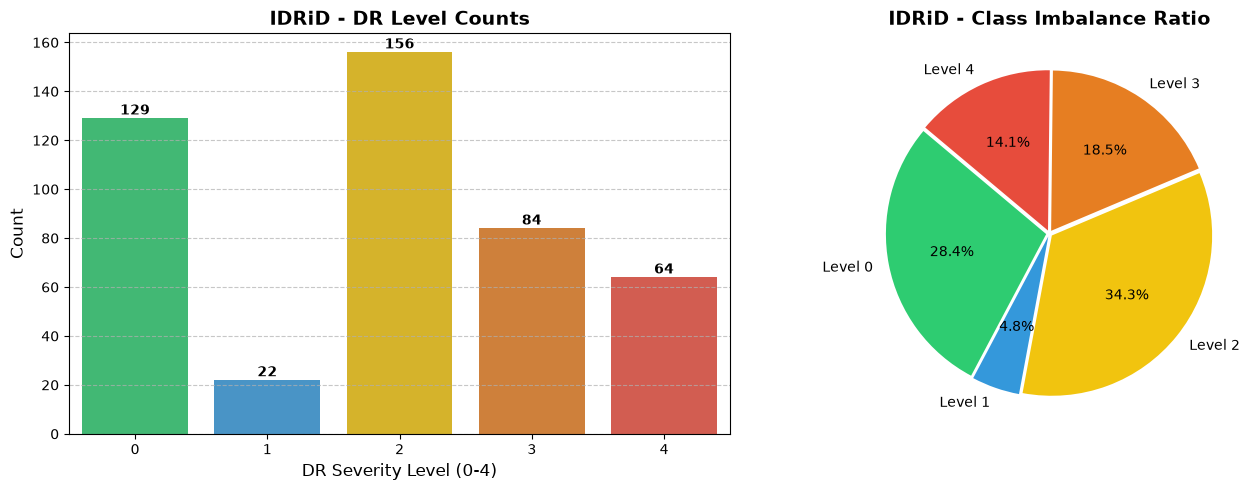

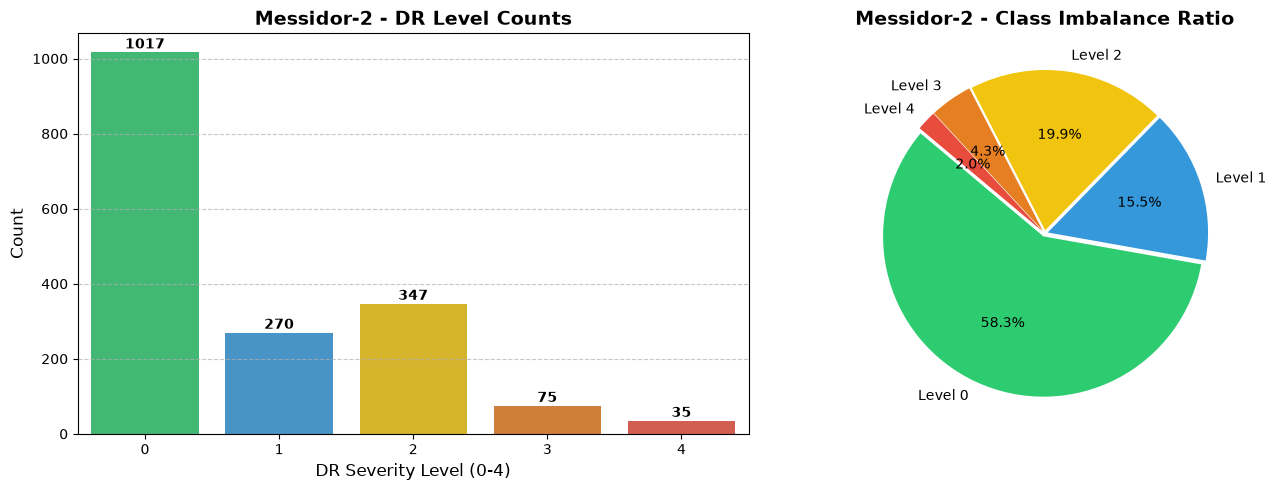

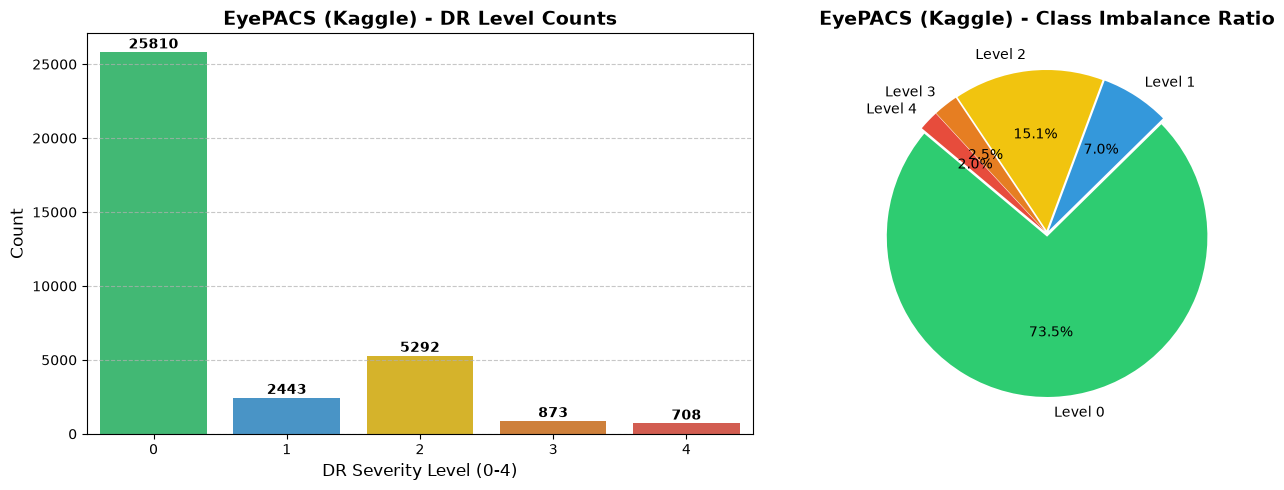

In [5]:
def plot_dataset_class_distribution(key: str, df: pd.DataFrame, title_name: str):
    counts = df["level"].value_counts().reindex(range(5), fill_value=0)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Barplot
    colors = ["#2ecc71", "#3498db", "#f1c40f", "#e67e22", "#e74c3c"]
    sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=colors)
    axes[0].set_title(f"{title_name} - DR Level Counts", fontsize=14, fontweight="bold")
    axes[0].set_xlabel("DR Severity Level (0-4)", fontsize=12)
    axes[0].set_ylabel("Count", fontsize=12)
    axes[0].grid(axis="y", linestyle="--", alpha=0.7)
    
    for i, count in enumerate(counts.values):
        axes[0].text(i, count + max(counts.values) * 0.01, f"{count}", ha="center", fontsize=10, fontweight="bold")
        
    # Pie chart
    axes[1].pie(counts.values, labels=[f"Level {i}" for i in range(5)], autopct="%1.1f%%", colors=colors, startangle=140, explode=[0.02]*5)
    axes[1].set_title(f"{title_name} - Class Imbalance Ratio", fontsize=14, fontweight="bold")
    
    plt.tight_layout()
    plt.show()

for key, df in dataset_dfs.items():
    plot_dataset_class_distribution(key, df, DATASET_CONFIG[key]["name"])



## 5. Visualizing Sample Images (1x5 Subplot Grid)

Renders 1 randomly sampled fundus photograph per DR grade (Level 0 through Level 4).



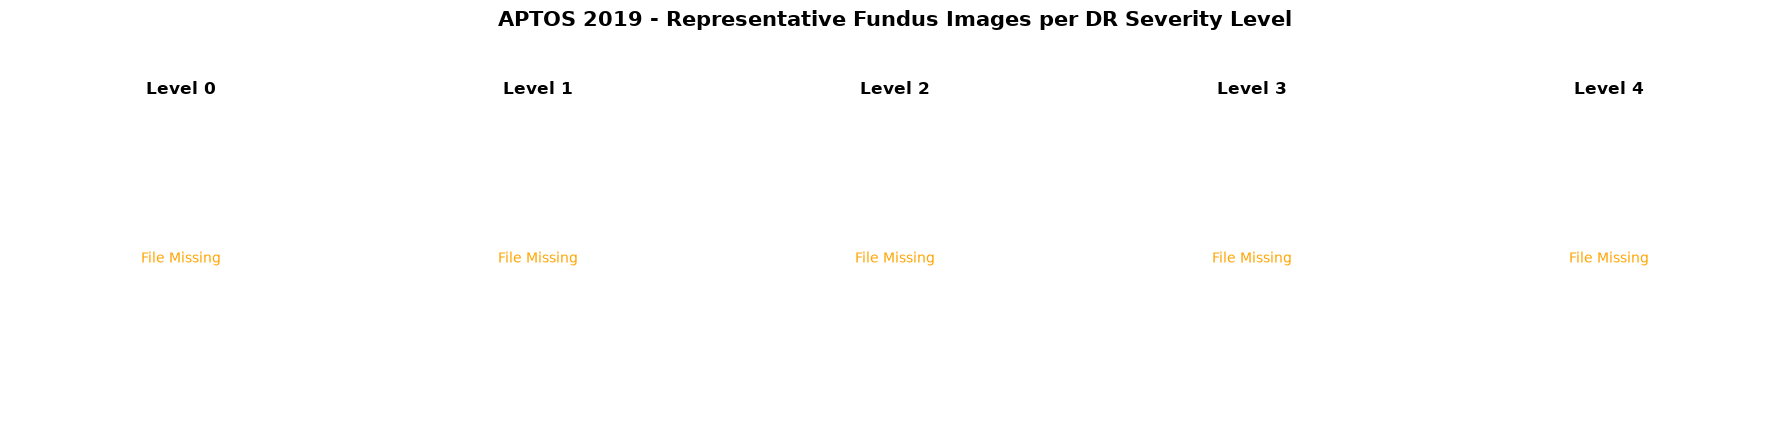

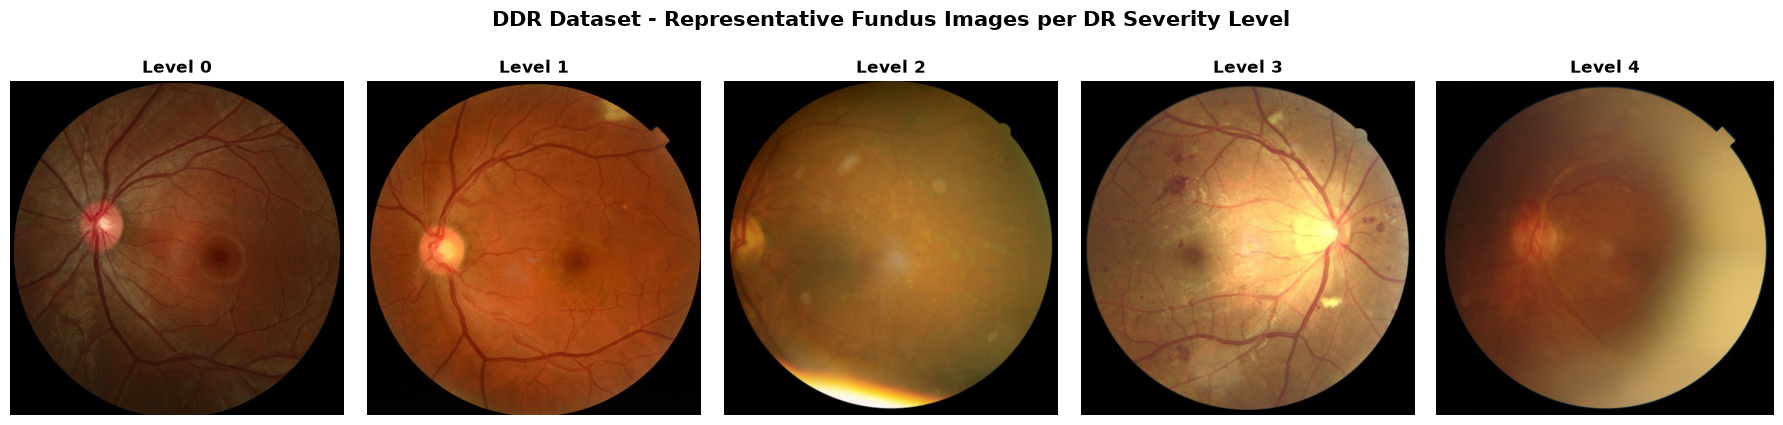

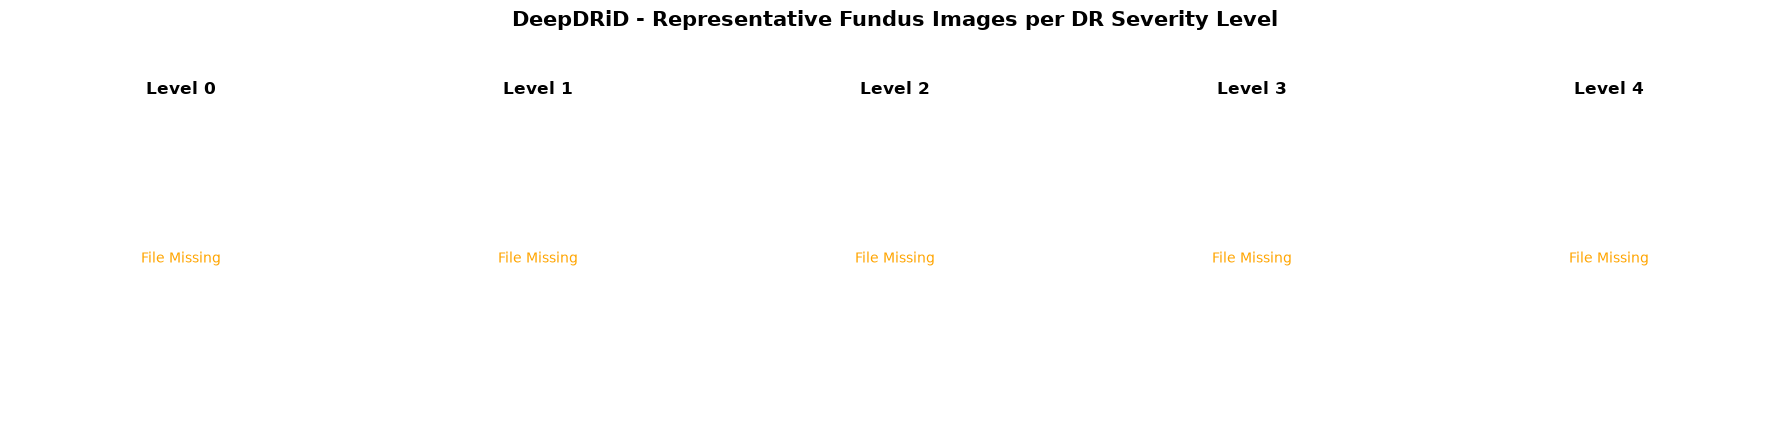

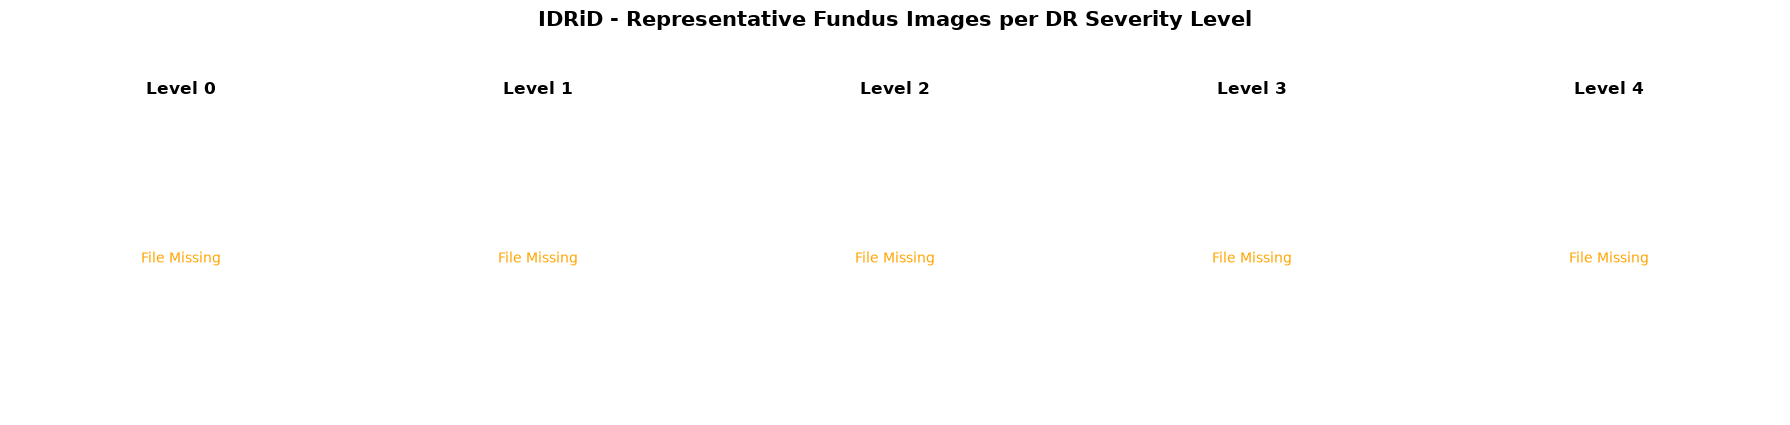

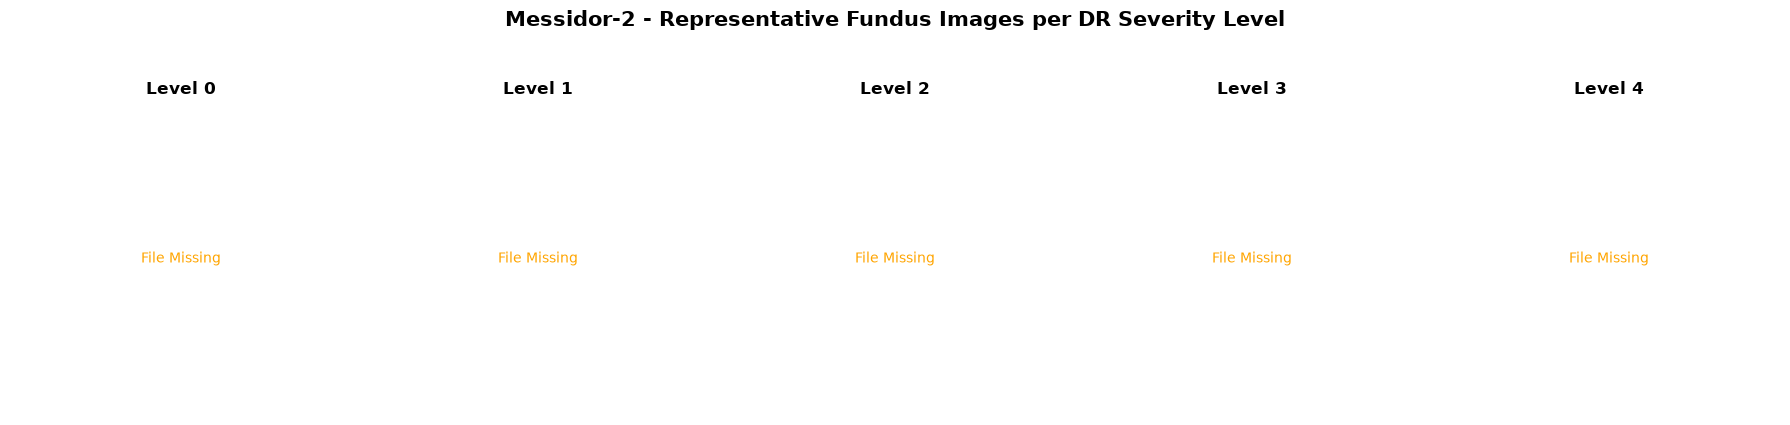

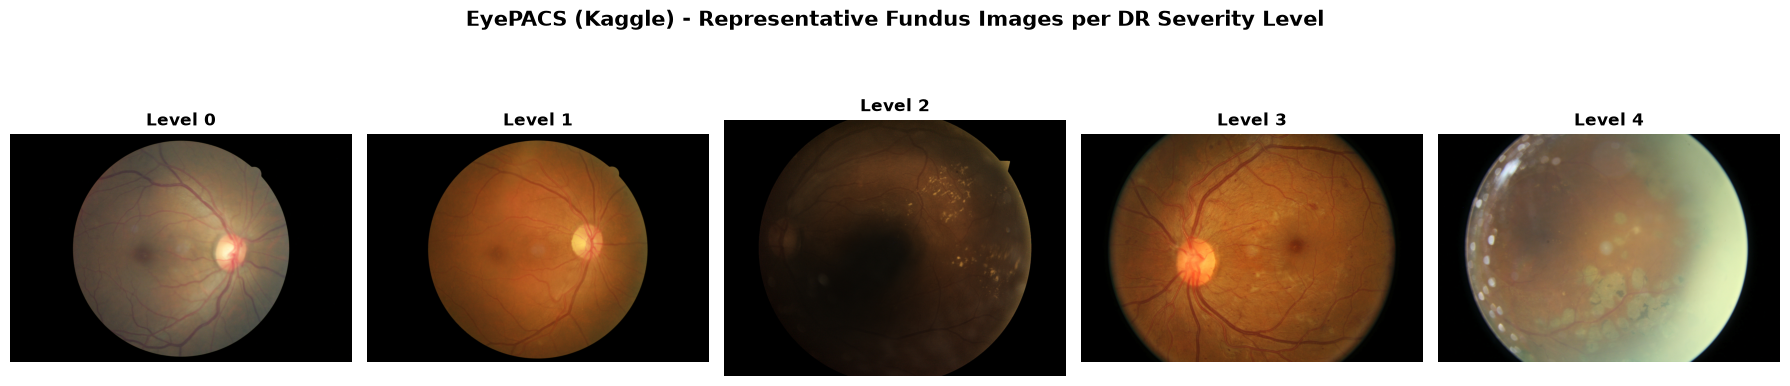

In [6]:
def plot_sample_images_per_level(key: str, df: pd.DataFrame, title_name: str):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    fig.suptitle(f"{title_name} - Representative Fundus Images per DR Severity Level", fontsize=15, fontweight="bold", y=1.05)
    
    for level in range(5):
        ax = axes[level]
        ax.set_title(f"Level {level}", fontsize=12, fontweight="bold")
        ax.axis("off")
        
        subset = df[df["level"] == level]
        if subset.empty:
            ax.text(0.5, 0.5, "No Image Available", ha="center", va="center", color="red", fontsize=10)
            continue
            
        sample_row = subset.sample(1, random_state=SEED).iloc[0]
        img_path = sample_row["full_path"]
        
        try:
            if not os.path.exists(img_path):
                ax.text(0.5, 0.5, "File Missing", ha="center", va="center", color="orange", fontsize=10)
                continue
                
            img = Image.open(img_path).convert("RGB")
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, "Read Error", ha="center", va="center", color="red", fontsize=10)
            print(f"[WARNING] Failed to load image {img_path}: {e}")
            
    plt.tight_layout()
    plt.show()

for key, df in dataset_dfs.items():
    plot_sample_images_per_level(key, df, DATASET_CONFIG[key]["name"])



## 6. Image Resolution & Quality Metric Sampling (100 Images / Dataset)

Extraction of Width, Height, Aspect Ratio, Grayscale Brightness, and OpenCV Laplacian Focus Variance.



In [7]:
def compute_image_metrics_sample(key: str, df: pd.DataFrame, sample_size: int = 100) -> pd.DataFrame:
    subset = df.sample(min(sample_size, len(df)), random_state=SEED)
    records = []
    
    for _, row in tqdm(subset.iterrows(), total=len(subset), desc=f"Sampling {key}"):
        img_path = row["full_path"]
        if not os.path.exists(img_path):
            continue
            
        try:
            # Resolution via PIL without decoding full image array
            with Image.open(img_path) as img:
                w, h = img.size
                aspect_ratio = w / h if h > 0 else 0
                
            # Quality metrics via OpenCV
            cv_img = cv2.imread(img_path)
            if cv_img is None:
                continue
                
            gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
            brightness = float(np.mean(gray))
            sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
            
            records.append({
                "dataset": DATASET_CONFIG[key]["name"],
                "image_id": row["image_id"],
                "level": row["level"],
                "width": w,
                "height": h,
                "aspect_ratio": aspect_ratio,
                "brightness": brightness,
                "sharpness": sharpness
            })
        except Exception as e:
            continue
            
    return pd.DataFrame(records)

all_metrics_list = []
for key, df in dataset_dfs.items():
    m_df = compute_image_metrics_sample(key, df, sample_size=100)
    all_metrics_list.append(m_df)

combined_metrics_df = pd.concat(all_metrics_list, ignore_index=True)



Sampling EyePACS: 100%|██████████| 100/100 [00:10<00:00,  9.24it/s]


## 7. Resolution & Quality Distribution Visualization



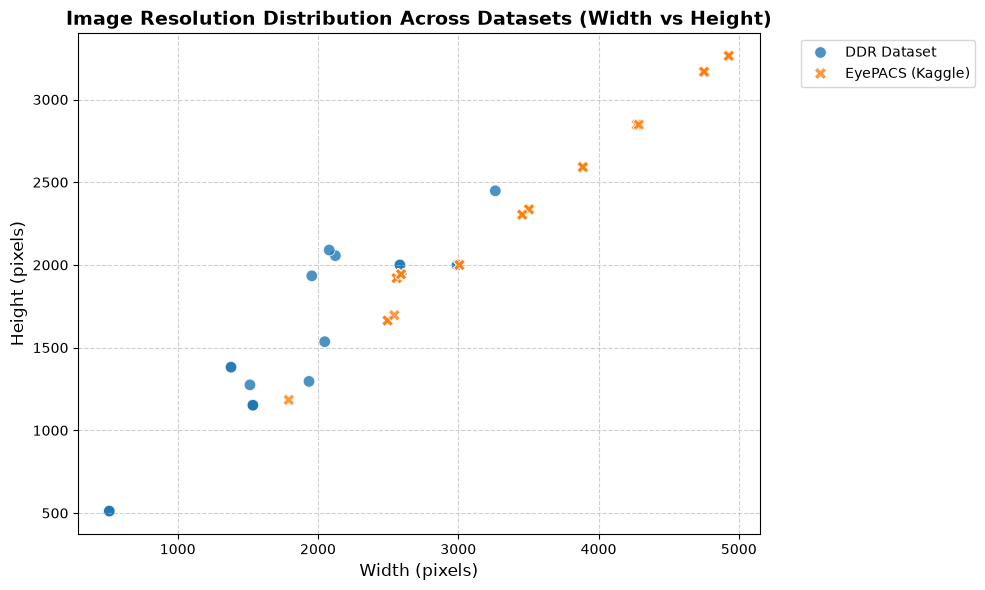

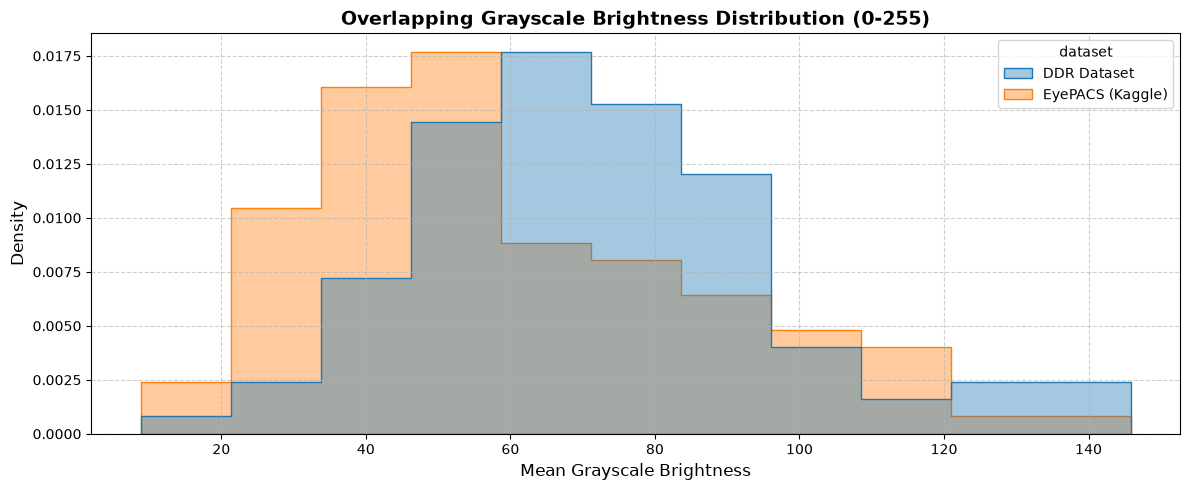

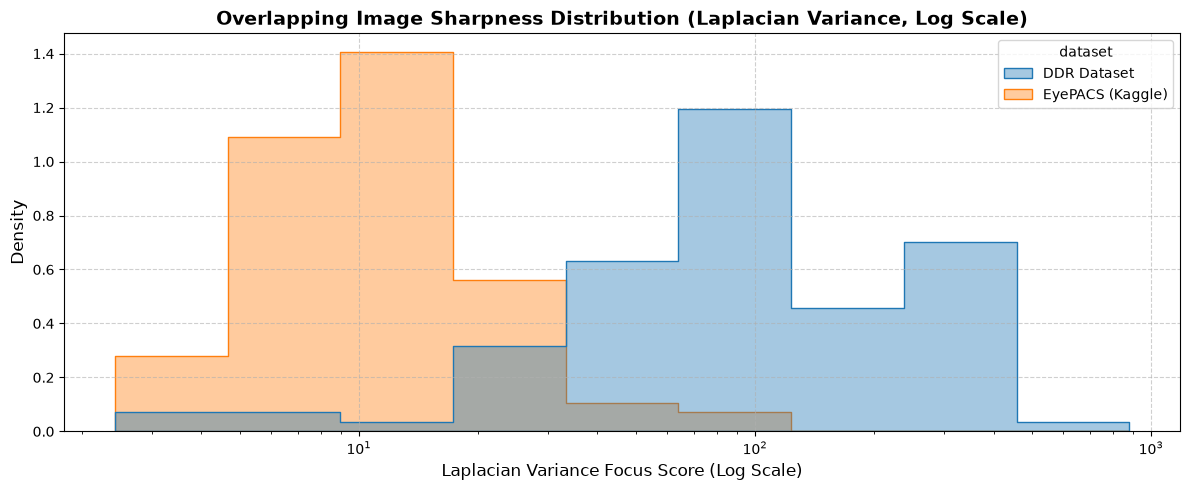

In [8]:
# Resolution Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=combined_metrics_df, 
    x="width", 
    y="height", 
    hue="dataset", 
    style="dataset",
    s=70, 
    alpha=0.8
)
plt.title("Image Resolution Distribution Across Datasets (Width vs Height)", fontsize=14, fontweight="bold")
plt.xlabel("Width (pixels)", fontsize=12)
plt.ylabel("Height (pixels)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Overlapping Brightness Histogram
plt.figure(figsize=(12, 5))
sns.histplot(
    data=combined_metrics_df, 
    x="brightness", 
    hue="dataset", 
    element="step", 
    stat="density", 
    common_norm=False, 
    alpha=0.4
)
plt.title("Overlapping Grayscale Brightness Distribution (0-255)", fontsize=14, fontweight="bold")
plt.xlabel("Mean Grayscale Brightness", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Overlapping Sharpness Histogram
plt.figure(figsize=(12, 5))
sns.histplot(
    data=combined_metrics_df, 
    x="sharpness", 
    hue="dataset", 
    element="step", 
    stat="density", 
    common_norm=False, 
    alpha=0.4,
    log_scale=True
)
plt.title("Overlapping Image Sharpness Distribution (Laplacian Variance, Log Scale)", fontsize=14, fontweight="bold")
plt.xlabel("Laplacian Variance Focus Score (Log Scale)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()



### Clinical & Biological Significance of Quality Audit

1. **Brightness Variances**: Differences in mean illumination reflect variations in flash power, fundus camera models, and pupil dilation status across medical centers. Applying **CLAHE (Contrast Limited Adaptive Histogram Equalization)** is essential to standardize local contrast and highlight microaneurysms and hemorrhages.
2. **Sharpness & Focus Blur**: Low Laplacian variance scores identify images degraded by motion blur, severe cataract opacity, or out-of-focus capture. Such artifacts obscure subtle lesions (cotton wool spots, neovascularization) and distort gradient-based attention (Grad-CAM). Blur-based filtering or automated quality screening is recommended prior to model ingestion.



## 8. Aggregated Multi-Source Hybrid Dataset Distribution

Simulates merging all 6 datasets into a unified multi-center training pool.



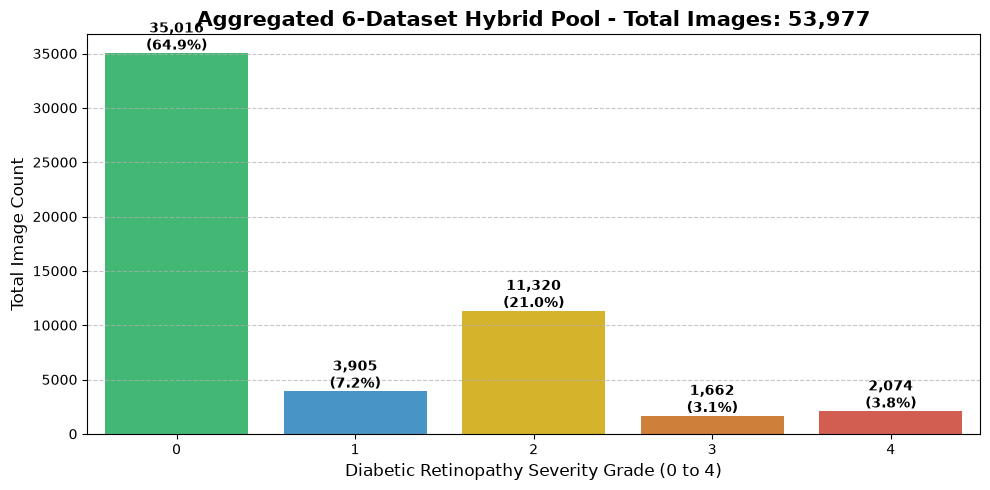


=== AGGREGATED HYBRID DATASET SUMMARY ===
Grade 0: 35,016 images (64.87%)
Grade 1: 3,905 images (7.23%)
Grade 2: 11,320 images (20.97%)
Grade 3: 1,662 images (3.08%)
Grade 4: 2,074 images (3.84%)
Total Combined Images: 53,977


In [9]:
combined_all_dfs = pd.concat(dataset_dfs.values(), ignore_index=True)

plt.figure(figsize=(10, 5))
agg_counts = combined_all_dfs["level"].value_counts().reindex(range(5), fill_value=0)
colors = ["#2ecc71", "#3498db", "#f1c40f", "#e67e22", "#e74c3c"]

ax = sns.barplot(x=agg_counts.index, y=agg_counts.values, palette=colors)
plt.title(f"Aggregated 6-Dataset Hybrid Pool - Total Images: {len(combined_all_dfs):,}", fontsize=15, fontweight="bold")
plt.xlabel("Diabetic Retinopathy Severity Grade (0 to 4)", fontsize=12)
plt.ylabel("Total Image Count", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

total_images = len(combined_all_dfs)
for i, count in enumerate(agg_counts.values):
    pct = (count / total_images) * 100
    ax.text(i, count + max(agg_counts.values) * 0.01, f"{count:,}\n({pct:.1f}%)", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

print("\n=== AGGREGATED HYBRID DATASET SUMMARY ===")
for grade in range(5):
    cnt = agg_counts[grade]
    print(f"Grade {grade}: {cnt:,} images ({cnt/total_images*100:.2f}%)")
print(f"Total Combined Images: {total_images:,}")
